In [37]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(dirname(os.getcwd())))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import IsaacCfg as cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.processing.vectorize import patchify

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
device = 'cuda:0'
model = create_agent(cf, device)
if isinstance(model, ActorCriticPerceiver):
    memories = create_memories(model.actor, cf.num_envs, device=device)
else:
    memories=None

In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
1

1

In [38]:
device = 'cuda:0'
model = create_agent(cf, device)
states = {}
# for i in range(4):
states['observations'] = torch.randn(cf.num_envs, 1, cf.dim_observations, device=device)
old_actions, _, _, new_mem = model(states, memories)

In [39]:
log_probs, _, _, _ = model(states, memories, old_actions)
log_probs.shape

torch.Size([2048])

In [33]:
for i in range(1000):
    tmp = torch.zeros(24, 1, 1, device=device)
    for i in range(4):
        states['observations'] = torch.rand(cf.num_envs, 1, 4, device=device)
    y_target =  states['observations'].detach().sum(dim=[1,2])

    _, values, _, memories = model(states, memories, torch.zeros(cf.num_envs, 1, 1, device=device))

    loss = F.mse_loss(values, y_target)
    print('std', values.std().item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # with torch.no_grad():  # No tracking of gradients during the update
    #     for param in model.parameters():
    #         if param.grad is not None:
    #             param -= 1e-4 * param.grad
    loss_all.append(loss.item())
    print('loss',loss.item())

std 0.3687824308872223
loss 5.013634654460475e-05
std 0.6519277691841125
loss 0.00010911200661212206
std 0.5576887726783752
loss 9.613518341211602e-05
std 0.5792022347450256
loss 7.148941222112626e-05
std 0.39094629883766174
loss 3.202456719009206e-05
std 0.804293692111969
loss 6.675993790850043e-05
std 0.4886171817779541
loss 2.6124518626602367e-05
std 0.5009599924087524
loss 0.0002083727449644357
std 0.575259268283844
loss 1.2801866432710085e-05
std 0.6770203113555908
loss 0.0006299277883954346
std 0.28340932726860046
loss 2.3498085283790715e-05
std 0.522583544254303
loss 2.372072049183771e-05
std 0.5428258180618286
loss 0.0001159475723397918
std 0.5452657341957092
loss 0.0006007037591189146
std 0.3285682797431946
loss 0.00011501210246933624
std 0.5315017104148865
loss 5.92834985582158e-05
std 0.5321999788284302
loss 5.270502879284322e-05
std 0.6820744276046753
loss 6.133371061878279e-05
std 0.646050751209259
loss 9.167127427645028e-05
std 0.3510778546333313
loss 1.752324533299543e-0

In [38]:
from matplotlib import pyplot as plt

In [34]:
print(y_target[:5])

tensor([2.3809, 1.8877, 1.0047, 2.5893, 0.6357], device='cuda:0')


In [35]:
print(values[:20])

tensor([2.6062, 1.7422, 1.5893, 1.6826, 1.4687, 1.5767, 1.6690, 2.6060, 1.6801,
        2.6368, 1.9303, 1.5252, 1.6414, 1.5201, 2.6483, 1.5580, 1.4705, 1.5879,
        2.3985, 1.6067], device='cuda:0', grad_fn=<SliceBackward0>)


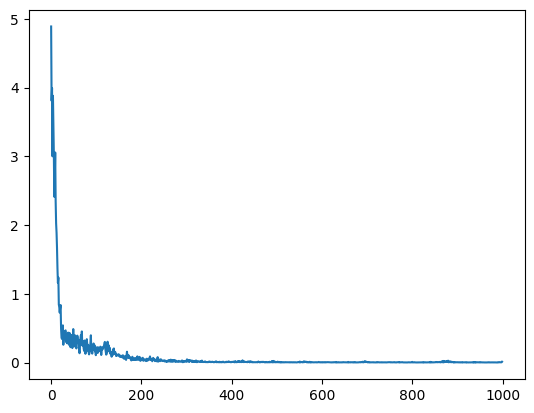

In [52]:
plt.plot(loss_all)